# ACA 1 – Análisis de precios de leche y precipitación en Cumbal

**Proyecto:** Sistema de alertas tempranas basado en inteligencia artificial para optimizar la utilidad y prevenir pérdidas económicas en asociaciones productoras de leche del municipio de Cumbal.

Este cuaderno procesa los archivos reales entregados:
- `leche-precios-20261031.csv` (Agronet, precios y volumen de acopio de Nariño).
- `52050110 cumbal dia.xlsx` (IDEAM, estación Cumbal 52050110).

**Alcance y precauciones:** los precios son departamentales (Nariño), mientras que la precipitación corresponde a una estación de Cumbal. La integración temporal permite explorar asociaciones, pero no equivale a medir costos, producción o rentabilidad de una asociación específica. No se entrena aquí un modelo predictivo ni se afirma que esté validado.

**Versión de trabajo:** v0.1 (análisis exploratorio; no constituye un modelo predictivo validado).

## 1. Cargar los archivos

En Google Colab, ejecuta la celda siguiente y selecciona ambos archivos. Si trabajas localmente, cambia las rutas en la celda de configuración.

In [1]:
# EN GOOGLE COLAB: ejecuta esta celda y selecciona los dos archivos fuente.
# Si ya están cargados en el entorno, puedes omitirla.
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    print("Entorno local detectado: se utilizarán los archivos presentes en la carpeta.")

Entorno local detectado: se utilizarán los archivos presentes en la carpeta.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import os

# Identificar archivos cargados
csv_candidates = [f for f in os.listdir('.') if f.lower().endswith('.csv') and 'leche' in f.lower()]
xlsx_candidates = [f for f in os.listdir('.') if f.lower().endswith('.xlsx') and '52050110' in f.lower()]

if not csv_candidates:
    raise FileNotFoundError("No se encontró el CSV de Agronet. Carga leche-precios-20261031.csv.")
if not xlsx_candidates:
    raise FileNotFoundError("No se encontró el Excel IDEAM. Carga 52050110 cumbal dia.xlsx.")

RUTA_AGRONET = csv_candidates[0]
RUTA_IDEAM = xlsx_candidates[0]
print("Agronet:", RUTA_AGRONET)
print("IDEAM:", RUTA_IDEAM)

Agronet: leche-precios-20261031.csv
IDEAM: 52050110 cumbal dia.xlsx


## 2. Cargar y revisar Agronet

In [3]:
agronet = pd.read_csv(RUTA_AGRONET)
print("Dimensiones:", agronet.shape)
display(agronet.head())
print("\\nColumnas:", agronet.columns.tolist())
print("\\nValores faltantes:")
display(agronet.isna().sum())

Dimensiones: (224, 5)


,Fecha,Departamento,Precio sin bonif. ($/Lt),Precio con bonif. ($/Lt),Volumen acopiado
0,2026-06,NARIÑO,1878.00,2064.00,12816227
1,2026-06,NARIÑO,1874.84,2066.37,10402674
2,2026-05,NARIÑO,1877.68,2066.99,10783916
3,2026-04,NARIÑO,1869.09,2068.02,10368268
4,2026-03,NARIÑO,1857.04,2067.10,10168746


\nColumnas: ['Fecha', 'Departamento', 'Precio sin bonif. ($/Lt)', 'Precio con bonif. ($/Lt)', 'Volumen acopiado']
\nValores faltantes:


Fecha                       0
Departamento                0
Precio sin bonif. ($/Lt)    0
Precio con bonif. ($/Lt)    0
Volumen acopiado            0
dtype: int64

In [4]:
# Conversión de tipos y validación
columnas_requeridas = [
    "Fecha", "Departamento", "Precio sin bonif. ($/Lt)",
    "Precio con bonif. ($/Lt)", "Volumen acopiado"
]
faltantes = [c for c in columnas_requeridas if c not in agronet.columns]
if faltantes:
    raise ValueError(f"Faltan columnas esperadas en Agronet: {faltantes}")

agronet["Fecha"] = pd.to_datetime(agronet["Fecha"].astype(str), format="%Y-%m", errors="coerce")
for c in ["Precio sin bonif. ($/Lt)", "Precio con bonif. ($/Lt)", "Volumen acopiado"]:
    agronet[c] = pd.to_numeric(agronet[c], errors="coerce")

print("Fechas no interpretadas:", agronet["Fecha"].isna().sum())
print("Fechas duplicadas (filas involucradas):", agronet["Fecha"].duplicated(keep=False).sum())
display(agronet[agronet["Fecha"].duplicated(keep=False)].sort_values("Fecha"))

Fechas no interpretadas: 0
Fechas duplicadas (filas involucradas): 2


,Fecha,Departamento,Precio sin bonif. ($/Lt),Precio con bonif. ($/Lt),Volumen acopiado
0,2026-06-01,NARIÑO,1878.00,2064.00,12816227
1,2026-06-01,NARIÑO,1874.84,2066.37,10402674


**Decisión de tratamiento:** no se eliminan automáticamente los registros repetidos de junio de 2026. Se conservan en la base original y, para la integración mensual, se calcula el promedio de precios y la suma del volumen. Esta regla debe documentarse y validarse con la fuente, pues los dos registros podrían representar reportes distintos.

## 3. Cargar y depurar IDEAM (estación 52050110 – Cumbal)

In [5]:
# El archivo contiene metadatos al inicio y filas de resumen mensual al final.
# Las observaciones diarias se identifican por una fecha válida en la primera columna.
ideam_raw = pd.read_excel(RUTA_IDEAM, header=None)
fechas = pd.to_datetime(ideam_raw.iloc[:, 0], errors="coerce")
mascara_diaria = fechas.notna()

ideam = ideam_raw.loc[mascara_diaria, [0, 2, 4]].copy()
ideam.columns = ["fecha", "precipitacion_mm", "nivel_aprobacion"]
ideam["fecha"] = pd.to_datetime(ideam["fecha"], errors="coerce")
ideam["precipitacion_mm"] = pd.to_numeric(ideam["precipitacion_mm"], errors="coerce")
ideam["nivel_aprobacion"] = ideam["nivel_aprobacion"].astype(str).str.strip()

print("Dimensiones diarias:", ideam.shape)
display(ideam.head())
display(ideam.tail())
print("\\nFaltantes:")
display(ideam.isna().sum())
print("\\nEstados de aprobación:")
display(ideam["nivel_aprobacion"].value_counts(dropna=False))

Dimensiones diarias: (7088, 3)


/tmp/ipykernel_776/4132676325.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  fechas = pd.to_datetime(ideam_raw.iloc[:, 0], errors="coerce")


,fecha,precipitacion_mm,nivel_aprobacion
8,2007-06-01,4.4,Definitivo
9,2007-06-02,3.5,Definitivo
10,2007-06-03,0.0,Definitivo
11,2007-06-04,3.1,Definitivo
12,2007-06-05,0.5,Definitivo


,fecha,precipitacion_mm,nivel_aprobacion
7091,2026-10-26,0.0,Preliminar
7092,2026-10-27,1.1,Preliminar
7093,2026-10-28,2.5,Preliminar
7094,2026-10-29,3.5,Preliminar
7095,2026-10-30,1.8,Preliminar


\nFaltantes:


fecha               0
precipitacion_mm    0
nivel_aprobacion    0
dtype: int64

\nEstados de aprobación:


nivel_aprobacion
Definitivo     4593
En revisión    1917
Preliminar      578
Name: count, dtype: int64

**Importante:** las filas de resumen mensual del archivo no se incorporan como registros diarios. La selección se basa en que la primera columna pueda interpretarse como fecha. El nivel de aprobación se conserva para distinguir datos definitivos, en revisión y preliminares.

## 4. Calidad y estadística descriptiva

Periodo: 2007-06-01 00:00:00 a 2026-10-30 00:00:00
Registros diarios: 7088
Duplicados de fecha: 0
Precipitación promedio (mm/día): 2.2786963882618507
Días con precipitación cero: 2966


count    7088.000000
mean        2.278696
std         4.504762
min         0.000000
25%         0.000000
50%         0.500000
75%         2.500000
max        78.500000
Name: precipitacion_mm, dtype: float64

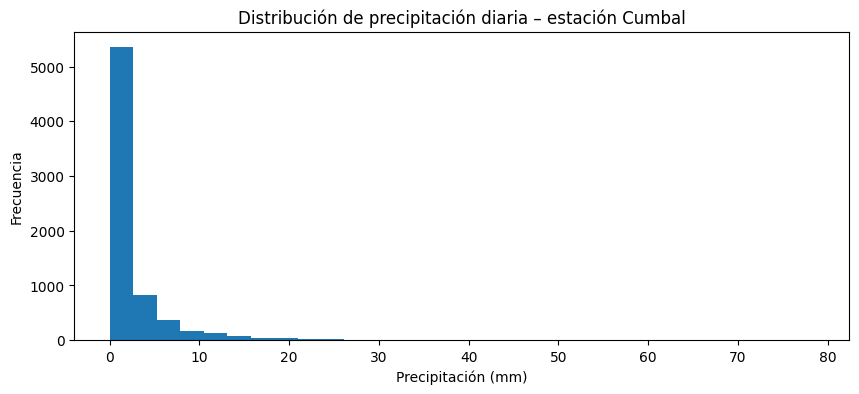

In [6]:
print("Periodo:", ideam["fecha"].min(), "a", ideam["fecha"].max())
print("Registros diarios:", len(ideam))
print("Duplicados de fecha:", ideam["fecha"].duplicated().sum())
print("Precipitación promedio (mm/día):", ideam["precipitacion_mm"].mean())
print("Días con precipitación cero:", (ideam["precipitacion_mm"] == 0).sum())
display(ideam["precipitacion_mm"].describe())

plt.figure(figsize=(10, 4))
plt.hist(ideam["precipitacion_mm"].dropna(), bins=30)
plt.title("Distribución de precipitación diaria – estación Cumbal")
plt.xlabel("Precipitación (mm)")
plt.ylabel("Frecuencia")
plt.show()

## 5. Agregación mensual e integración de fuentes

In [7]:
ideam["mes"] = ideam["fecha"].dt.to_period("M").dt.to_timestamp()

ideam_mensual = ideam.groupby("mes").agg(
    precipitacion_total_mm=("precipitacion_mm", "sum"),
    precipitacion_promedio_diaria_mm=("precipitacion_mm", "mean"),
    dias_con_dato=("precipitacion_mm", "count"),
    dias_lluvia=("precipitacion_mm", lambda s: (s > 0).sum())
).reset_index()

agronet_mensual = agronet.groupby("Fecha", as_index=False).agg(
    departamento=("Departamento", "first"),
    precio_sin_bonif_cop_lt=("Precio sin bonif. ($/Lt)", "mean"),
    precio_con_bonif_cop_lt=("Precio con bonif. ($/Lt)", "mean"),
    volumen_acopiado=("Volumen acopiado", "sum"),
    registros_agronet=("Departamento", "size")
).rename(columns={"Fecha": "mes"})

integrada = agronet_mensual.merge(ideam_mensual, on="mes", how="inner")
print("Meses Agronet:", len(agronet_mensual))
print("Meses IDEAM:", len(ideam_mensual))
print("Meses coincidentes:", len(integrada))
display(integrada.head())

Meses Agronet: 223
Meses IDEAM: 233
Meses coincidentes: 218


,mes,departamento,precio_sin_bonif_cop_lt,precio_con_bonif_cop_lt,volumen_acopiado,registros_agronet,precipitacion_total_mm,precipitacion_promedio_diaria_mm,dias_con_dato,dias_lluvia
0,2007-06-01,NARIÑO,561.166459,663.955998,2584595,1,29.7,0.990000,30,19
1,2007-07-01,NARIÑO,597.999404,715.428570,9219494,1,50.1,1.616129,31,11
2,2007-08-01,NARIÑO,604.328077,715.619151,5975259,1,25.4,0.819355,31,16
3,2007-09-01,NARIÑO,601.911550,671.509748,9150734,1,11.0,0.366667,30,6
4,2007-10-01,NARIÑO,600.698473,719.342933,9207999,1,158.1,5.100000,31,21


## 6. Análisis exploratorio y correlaciones

Las correlaciones son exploratorias y no prueban causalidad. La interpretación debe considerar que el precio de Agronet representa Nariño y no necesariamente el precio recibido por cada asociación de Cumbal.

In [8]:
variables = [
    "precio_sin_bonif_cop_lt", "precio_con_bonif_cop_lt",
    "volumen_acopiado", "precipitacion_total_mm",
    "precipitacion_promedio_diaria_mm"
]
display(integrada[variables].describe().T)
display(integrada[variables].corr(method="pearson"))
display(integrada[variables].corr(method="spearman"))

,count,mean,std,min,25%,50%,75%,max
precio_sin_bonif_cop_lt,218.0,1.067489e+03,3.835110e+02,5.611665e+02,7.696500e+02,9.594950e+02,1.247188e+03,2.026030e+03
precio_con_bonif_cop_lt,218.0,1.158358e+03,4.447992e+02,6.639560e+02,8.169325e+02,1.019715e+03,1.457930e+03,2.072840e+03
volumen_acopiado,218.0,9.791745e+06,1.976704e+06,2.584595e+06,8.616079e+06,9.618920e+06,1.077796e+07,2.321890e+07
precipitacion_total_mm,218.0,7.024358e+01,4.674911e+01,5.900000e+00,3.222500e+01,5.945000e+01,9.230000e+01,2.229000e+02
precipitacion_promedio_diaria_mm,218.0,2.310209e+00,1.531810e+00,1.966667e-01,1.049750e+00,1.969286e+00,3.046129e+00,7.190323e+00


,precio_sin_bonif_cop_lt,precio_con_bonif_cop_lt,volumen_acopiado,precipitacion_total_mm,precipitacion_promedio_diaria_mm
precio_sin_bonif_cop_lt,1.000000,0.977955,0.563124,-0.190314,-0.190388
precio_con_bonif_cop_lt,0.977955,1.000000,0.592849,-0.177671,-0.177334
volumen_acopiado,0.563124,0.592849,1.000000,-0.164147,-0.170443
precipitacion_total_mm,-0.190314,-0.177671,-0.164147,1.000000,0.998713
precipitacion_promedio_diaria_mm,-0.190388,-0.177334,-0.170443,0.998713,1.000000


,precio_sin_bonif_cop_lt,precio_con_bonif_cop_lt,volumen_acopiado,precipitacion_total_mm,precipitacion_promedio_diaria_mm
precio_sin_bonif_cop_lt,1.000000,0.989515,0.712968,-0.161310,-0.160341
precio_con_bonif_cop_lt,0.989515,1.000000,0.720321,-0.143457,-0.142172
volumen_acopiado,0.712968,0.720321,1.000000,-0.162180,-0.167527
precipitacion_total_mm,-0.161310,-0.143457,-0.162180,1.000000,0.998751
precipitacion_promedio_diaria_mm,-0.160341,-0.142172,-0.167527,0.998751,1.000000


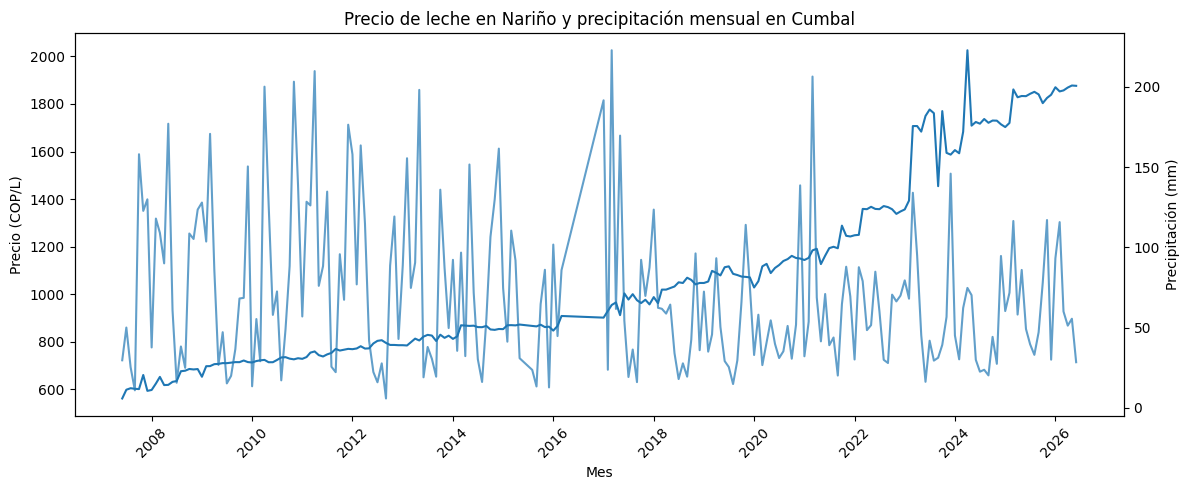

In [9]:
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(integrada["mes"], integrada["precio_sin_bonif_cop_lt"], label="Precio sin bonificación (COP/L)")
ax1.set_xlabel("Mes")
ax1.set_ylabel("Precio (COP/L)")
ax1.tick_params(axis="x", rotation=45)
ax2 = ax1.twinx()
ax2.plot(integrada["mes"], integrada["precipitacion_total_mm"], label="Precipitación mensual (mm)", alpha=0.7)
ax2.set_ylabel("Precipitación (mm)")
plt.title("Precio de leche en Nariño y precipitación mensual en Cumbal")
fig.tight_layout()
plt.show()

## 7.1 Diccionario de datos y calidad
Se documentan tipo, faltantes y valores descriptivos de las variables efectivamente disponibles. Los rangos observados son descriptivos, no límites normativos.

In [10]:
# Diccionario reproducible de Agronet e IDEAM
diccionario = pd.DataFrame([
    ["Fecha", "fecha mensual", "Mes de referencia del precio", "Agronet"],
    ["Departamento", "texto", "Departamento reportado por Agronet", "Agronet"],
    ["Precio sin bonif. ($/Lt)", "numérico", "Precio por litro sin bonificación, COP/L", "Agronet"],
    ["Precio con bonif. ($/Lt)", "numérico", "Precio por litro con bonificación, COP/L", "Agronet"],
    ["Volumen acopiado", "numérico", "Volumen reportado por Agronet; conservar unidad original", "Agronet"],
    ["fecha", "fecha diaria", "Fecha de observación meteorológica", "IDEAM"],
    ["precipitacion_mm", "numérico", "Precipitación diaria en milímetros", "IDEAM"],
    ["nivel_aprobacion", "categórico", "Estado de aprobación reportado en el archivo", "IDEAM"]
], columns=["variable", "tipo", "descripcion_unidad", "fuente"])
calidad_agronet = pd.DataFrame({"variable": agronet.columns, "tipo": [str(agronet[c].dtype) for c in agronet.columns], "faltantes": agronet.isna().sum().values, "porcentaje_faltante": (agronet.isna().mean().values*100).round(2)})
calidad_ideam = pd.DataFrame({"variable": ideam.columns, "tipo": [str(ideam[c].dtype) for c in ideam.columns], "faltantes": ideam.isna().sum().values, "porcentaje_faltante": (ideam.isna().mean().values*100).round(2)})
print("Calidad Agronet"); display(calidad_agronet)
print("Calidad IDEAM"); display(calidad_ideam)
display(diccionario)

Calidad Agronet


,variable,tipo,faltantes,porcentaje_faltante
0,Fecha,datetime64[ns],0,0.0
1,Departamento,object,0,0.0
2,Precio sin bonif. ($/Lt),float64,0,0.0
3,Precio con bonif. ($/Lt),float64,0,0.0
4,Volumen acopiado,int64,0,0.0


Calidad IDEAM


,variable,tipo,faltantes,porcentaje_faltante
0,fecha,datetime64[ns],0,0.0
1,precipitacion_mm,float64,0,0.0
2,nivel_aprobacion,object,0,0.0
3,mes,datetime64[ns],0,0.0


,variable,tipo,descripcion_unidad,fuente
0,Fecha,fecha mensual,Mes de referencia del precio,Agronet
1,Departamento,texto,Departamento reportado por Agronet,Agronet
2,Precio sin bonif. ($/Lt),numérico,"Precio por litro sin bonificación, COP/L",Agronet
3,Precio con bonif. ($/Lt),numérico,"Precio por litro con bonificación, COP/L",Agronet
4,Volumen acopiado,numérico,Volumen reportado por Agronet; conservar unida...,Agronet
5,fecha,fecha diaria,Fecha de observación meteorológica,IDEAM
6,precipitacion_mm,numérico,Precipitación diaria en milímetros,IDEAM
7,nivel_aprobacion,categórico,Estado de aprobación reportado en el archivo,IDEAM


## 7.2 Duplicados, valores atípicos y decisión de tratamiento
Se cuantifican duplicados y posibles atípicos mediante el criterio del rango intercuartílico (IQR). Los registros no se eliminan automáticamente: se reportan para revisión contextual.

In [11]:
def resumen_iqr(df, columnas):
    filas=[]
    for c in columnas:
        s=pd.to_numeric(df[c], errors="coerce").dropna()
        if len(s)==0: continue
        q1,q3=s.quantile([.25,.75]); iqr=q3-q1
        li,ls=q1-1.5*iqr,q3+1.5*iqr
        filas.append([c,len(s),q1,q3,li,ls,((s<li)|(s>ls)).sum()])
    return pd.DataFrame(filas,columns=["variable","n_validos","q1","q3","limite_inferior_iqr","limite_superior_iqr","posibles_atipicos"])
print("Duplicados Agronet por fecha:", agronet["Fecha"].duplicated(keep=False).sum())
print("Duplicados IDEAM por fecha:", ideam["fecha"].duplicated(keep=False).sum())
display(resumen_iqr(agronet,["Precio sin bonif. ($/Lt)","Precio con bonif. ($/Lt)","Volumen acopiado"]))
display(resumen_iqr(ideam,["precipitacion_mm"]))

Duplicados Agronet por fecha: 2
Duplicados IDEAM por fecha: 0


,variable,n_validos,q1,q3,limite_inferior_iqr,limite_superior_iqr,posibles_atipicos
0,Precio sin bonif. ($/Lt),224,7.618560e+02,1.246043e+03,3.557618e+01,1.972322e+03,1
1,Precio con bonif. ($/Lt),224,8.032221e+02,1.430490e+03,-1.376797e+02,2.371392e+03,0
2,Volumen acopiado,224,8.564834e+06,1.074386e+07,5.296301e+06,1.401239e+07,6


,variable,n_validos,q1,q3,limite_inferior_iqr,limite_superior_iqr,posibles_atipicos
0,precipitacion_mm,7088,0.0,2.5,-3.75,6.25,736


## 7.3 Análisis temporal, correlaciones y multicolinealidad
Las asociaciones se interpretan como exploratorias. Las series son observacionales y tienen cobertura geográfica distinta; correlación no implica causalidad. El VIF se calcula solo para variables numéricas completas y se reporta como diagnóstico, no como prueba causal.

In [12]:
# Matriz de correlación con observaciones completas
vars_corr=[c for c in ["precio_sin_bonif_cop_lt","precio_con_bonif_cop_lt","volumen_acopiado","precipitacion_total_mm","precipitacion_promedio_diaria_mm"] if c in integrada.columns]
pearson=integrada[vars_corr].corr(method="pearson"); spearman=integrada[vars_corr].corr(method="spearman")
print("Correlación Pearson"); display(pearson.round(3))
print("Correlación Spearman"); display(spearman.round(3))

# VIF para regresores disponibles. Se excluye una de las dos versiones del precio para evitar usar ambas como predictores simultáneos.
try:
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    from statsmodels.tools.tools import add_constant
    pred=[c for c in ["volumen_acopiado","precipitacion_total_mm","precipitacion_promedio_diaria_mm"] if c in integrada.columns]
    X=integrada[pred].replace([np.inf,-np.inf],np.nan).dropna()
    if len(pred)>=2 and len(X)>len(pred)+1:
        Xc=add_constant(X,has_constant="add")
        vif=pd.DataFrame({"variable":Xc.columns,"VIF":[variance_inflation_factor(Xc.values,i) for i in range(Xc.shape[1])]})
        display(vif.round(3))
    else: print("VIF no calculado: cantidad insuficiente de variables u observaciones completas.")
except Exception as e: print("No fue posible calcular VIF en este entorno:",e)

# Tendencia descriptiva del precio (sin ajuste por inflación)
if len(integrada)>=3:
    z=integrada[["mes","precio_sin_bonif_cop_lt"]].dropna().copy()
    z["indice_tiempo"]=np.arange(len(z))
    coef=np.polyfit(z["indice_tiempo"],z["precio_sin_bonif_cop_lt"],1)[0]
    print("Pendiente lineal descriptiva del precio (COP/L por observación mensual):",round(coef,3))
    print("Nota: precios nominales; no se ha aplicado ajuste por inflación ni desestacionalización.")

Correlación Pearson


,precio_sin_bonif_cop_lt,precio_con_bonif_cop_lt,volumen_acopiado,precipitacion_total_mm,precipitacion_promedio_diaria_mm
precio_sin_bonif_cop_lt,1.000,0.978,0.563,-0.190,-0.190
precio_con_bonif_cop_lt,0.978,1.000,0.593,-0.178,-0.177
volumen_acopiado,0.563,0.593,1.000,-0.164,-0.170
precipitacion_total_mm,-0.190,-0.178,-0.164,1.000,0.999
precipitacion_promedio_diaria_mm,-0.190,-0.177,-0.170,0.999,1.000


Correlación Spearman


,precio_sin_bonif_cop_lt,precio_con_bonif_cop_lt,volumen_acopiado,precipitacion_total_mm,precipitacion_promedio_diaria_mm
precio_sin_bonif_cop_lt,1.000,0.990,0.713,-0.161,-0.160
precio_con_bonif_cop_lt,0.990,1.000,0.720,-0.143,-0.142
volumen_acopiado,0.713,0.720,1.000,-0.162,-0.168
precipitacion_total_mm,-0.161,-0.143,-0.162,1.000,0.999
precipitacion_promedio_diaria_mm,-0.160,-0.142,-0.168,0.999,1.000


,variable,VIF
0,const,31.898
1,volumen_acopiado,1.045
2,precipitacion_total_mm,394.520
3,precipitacion_promedio_diaria_mm,395.376


Pendiente lineal descriptiva del precio (COP/L por observación mensual): 5.706
Nota: precios nominales; no se ha aplicado ajuste por inflación ni desestacionalización.


## 7.4 Protocolo propuesto para evaluar un modelo futuro
**No se entrena un modelo predictivo en esta versión**, porque las fuentes disponibles no contienen costos reales, ingresos y producción de las asociaciones. Cuando se obtengan esos datos, se propone: (i) definir como variable objetivo el costo unitario por litro (COP/L), si está disponible de forma consistente; (ii) separar cronológicamente entrenamiento y prueba, sin mezclar meses futuros en el entrenamiento; (iii) validar con ventanas temporales expansivas; (iv) comparar con una línea base ingenua que prediga el último valor observado; (v) reportar MAE, RMSE y R², evitando MAPE cuando existan ceros o valores cercanos a cero; y (vi) considerar mejora frente a la línea base como criterio mínimo. El protocolo deberá ajustarse al tamaño y calidad de la muestra.

## 7.5 Exportación de tablas de auditoría
Además de las bases, se exportan diccionario, calidad, correlaciones y posibles atípicos para respaldar la trazabilidad del análisis.

In [13]:
with pd.ExcelWriter("resultados_ACA1_Cumbal.xlsx", engine="openpyxl") as writer:
    agronet.to_excel(writer,sheet_name="Agronet_limpio",index=False)
    ideam.to_excel(writer,sheet_name="IDEAM_diario",index=False)
    ideam_mensual.to_excel(writer,sheet_name="IDEAM_mensual",index=False)
    integrada.to_excel(writer,sheet_name="Base_integrada",index=False)
    diccionario.to_excel(writer,sheet_name="Diccionario",index=False)
    calidad_agronet.to_excel(writer,sheet_name="Calidad_Agronet",index=False)
    calidad_ideam.to_excel(writer,sheet_name="Calidad_IDEAM",index=False)
    pearson.to_excel(writer,sheet_name="Pearson")
    spearman.to_excel(writer,sheet_name="Spearman")
print("Excel de auditoría actualizado: resultados_ACA1_Cumbal.xlsx")

Excel de auditoría actualizado: resultados_ACA1_Cumbal.xlsx


## 7. Exportar bases depuradas y resultados

Se exportan las bases para trazabilidad. Conserva también los archivos originales sin modificación.

In [14]:
with pd.ExcelWriter("resultados_ACA1_Cumbal.xlsx", engine="openpyxl") as writer:
    agronet.to_excel(writer, sheet_name="Agronet_limpio", index=False)
    ideam.to_excel(writer, sheet_name="IDEAM_diario", index=False)
    ideam_mensual.to_excel(writer, sheet_name="IDEAM_mensual", index=False)
    integrada.to_excel(writer, sheet_name="Base_integrada", index=False)

print("Archivo generado: resultados_ACA1_Cumbal.xlsx")
# En Google Colab, si deseas descargarlo, ejecuta en una celda aparte:
# from google.colab import files
# files.download("resultados_ACA1_Cumbal.xlsx")

Archivo generado: resultados_ACA1_Cumbal.xlsx


## 8. Hallazgos y limitaciones para documentar en el ACA

1. Agronet contiene 224 filas y cinco variables; junio de 2026 aparece en dos registros. La integración mensual promedia precios y suma volumen, dejando explícita esta decisión.
2. IDEAM contiene 7.088 observaciones diarias identificables entre el 1 de junio de 2007 y el 30 de octubre de 2026. Se separaron las filas de metadatos y los resúmenes mensuales.
3. La precipitación diaria promedio observada en el archivo es aproximadamente 2,28 mm; 2.966 días registran cero precipitación.
4. La estación contiene distintos niveles de aprobación. Para análisis sensibles se recomienda repetir resultados usando únicamente registros “Definitivo” y comparar con la serie completa.
5. Las fuentes tienen diferente cobertura geográfica y naturaleza: precios de leche para Nariño y precipitación de una estación de Cumbal. No permiten concluir directamente la utilidad o pérdidas de una asociación.
6. Para entrenar y validar un sistema de alertas se requieren datos propios de las asociaciones: litros producidos, costos por rubro, ingresos, mermas, calidad, frecuencia de recolección y registros históricos comparables.

**No afirmar:** que se entrenó o validó un modelo predictivo, ni que existe capacidad predictiva demostrada, hasta ejecutar y documentar el protocolo de evaluación con datos suficientes.